# IMDb Movie Review Sentiment Analysis 🎬

An end-to-end Natural Language Processing (NLP) pipeline built to clean, tokenize, and analyze text from the 50,000 IMDb movie reviews dataset.

## 🚀 Key Features
* **Advanced Text Cleaning:** Custom Python and Regex functions to handle contractions, slang/abbreviations, HTML tags, URLs, special characters, and lowercasing.
* **Tokenization & Stopword Removal:** Leverages `NLTK` for tokenization and efficient stopword filtering.
* **Exploratory Data Analysis (EDA):** Feature extraction calculating character lengths, word counts, and review distribution patterns.

## 🛠️ Tech Stack
* **Language:** Python
* **Libraries:** Pandas, NumPy, Regular Expressions (`re`), NLTK, Matplotlib, Seaborn
* **Environment:** Jupyter Notebook / Visual Studio Code

In [1]:
import pandas as pd
import numpy as np

In [2]:
df= pd.read_csv('D:\python\pandas datasets\IMDB Dataset.csv')

In [3]:
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [5]:
df.shape

(50000, 2)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     50000 non-null  str  
 1   sentiment  50000 non-null  str  
dtypes: str(2)
memory usage: 63.6 MB


In [8]:
df['review'][0]

"One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />I would say the main appeal of the show is due to the fa

# Data Cleaning
## Lowercase conversion, whitespace trimming, HTML removal, URL removal, punctuation and special-character removal.

In [10]:
# converting data to lowecase
df['review'] = df['review'].str.lower()

In [11]:
# removing white spaces 
df['review'] = df['review'].str.strip()

In [12]:
# removing html tags
import re
def remove_html(data):
  return re.sub(r"<.*?>", "", data)

df['review'] = df['review'].apply(remove_html)

In [13]:
def remove_extra_chars(data):

    data = re.sub(r'\.{2,}', '', data)  
    data = data.replace("''", '')       
    return data

df['review'] = df['review'].apply(remove_extra_chars)

In [14]:
# removing urls
def remove_url(data):
    return re.sub(r'https?://\S+|www\.\S+', '', data)
df['review'] = df['review'].apply(remove_url)

In [15]:
# Expanding abbreviations
def remove_abb(data):
  data = re.sub(r"\bain't\b", "am not", data)
  data = re.sub(r"\baren't\b", "are not", data)
  data = re.sub(r"\bcan't\b", "cannot", data)
  data = re.sub(r"\bcan't've\b", "cannot have", data)
  data = re.sub(r"\b'cause\b", "because", data)
  data = re.sub(r"\bcould've\b", "could have", data)
  data = re.sub(r"\bcouldn't\b", "could not", data)
  data = re.sub(r"\bdidn't\b", "did not", data)
  data = re.sub(r"\bdoesn't\b", "does not", data)
  data = re.sub(r"\bdon't\b", "do not", data)
  data = re.sub(r"\bhadn't\b", "had not", data)
  data = re.sub(r"\bhasn't\b", "has not", data)
  data = re.sub(r"\bhaven't\b", "have not", data)
  data = re.sub(r"\bhe'd\b", "he would", data)
  data = re.sub(r"\bhe'll\b", "he will", data)
  data = re.sub(r"\bhe's\b", "he is", data)
  data = re.sub(r"\bi'd\b", "I would", data)
  data = re.sub(r"\bi'll\b", "I will", data)
  data = re.sub(r"\bi'm\b", "I am", data)
  data = re.sub(r"\bi've\b", "I have", data)
  data = re.sub(r"\bisn't\b", "is not", data)
  data = re.sub(r"\bit'd\b", "it would", data)
  data = re.sub(r"\bit'll\b", "it will", data)
  data = re.sub(r"\bit's\b", "it is", data)
  data = re.sub(r"\blet's\b", "let us", data)
  data = re.sub(r"\bmightn't\b", "might not", data)
  data = re.sub(r"\bmustn't\b", "must not", data)
  data = re.sub(r"\bshan't\b", "shall not", data)
  data = re.sub(r"\bshe'd\b", "she would", data)
  data = re.sub(r"\bshe'll\b", "she will", data)
  data = re.sub(r"\bshe's\b", "she is", data)
  data = re.sub(r"\bshouldn't\b", "should not", data)
  data = re.sub(r"\bthat's\b", "that is", data)
  data = re.sub(r"\bthere's\b", "there is", data)
  data = re.sub(r"\bthey'd\b", "they would", data)
  data = re.sub(r"\bthey'll\b", "they will", data)
  data = re.sub(r"\bthey're\b", "they are", data)
  data = re.sub(r"\bthey've\b", "they have", data)
  data = re.sub(r"\bwasn't\b", "was not", data)
  data = re.sub(r"\bwe'd\b", "we would", data)
  data = re.sub(r"\bwe're\b", "we are", data)
  data = re.sub(r"\bwe've\b", "we have", data)
  data = re.sub(r"\bweren't\b", "were not", data)
  data = re.sub(r"\bwhat're\b", "what are", data)
  data = re.sub(r"\bwhat's\b", "what is", data)
  data = re.sub(r"\bwhere's\b", "where is", data)
  data = re.sub(r"\bwho's\b", "who is", data)
  data = re.sub(r"\bwon't\b", "will not", data)
  data = re.sub(r"\bwouldn't\b", "would not", data)
  data = re.sub(r"\byou'd\b", "you would", data)
  data = re.sub(r"\byou'll\b", "you will", data)
  data = re.sub(r"\byou're\b", "you are", data)
  data = re.sub(r"\byou've\b", "you have", data)
  return data

df['review'] = df['review'].apply(remove_abb)

In [16]:
# removing punctuations
import string

def remove_punctuation(text):
    return text.translate(str.maketrans('', '', string.punctuation))

df['review'] = df['review'].apply(remove_punctuation)

In [17]:
# removing Special characters
def remove_special_chars(text):
  return re.sub(r'[^a-zA-Z0-9\s]', '', text)
df['review'] = df['review'].apply(remove_special_chars)

# Pre Processing
## NLTK tokenization, stop-word removal, and joining tokens back into text. 

In [18]:
# Tokenizaion
import nltk
from nltk.tokenize import word_tokenize
df['tokenized_review']= df['review'].apply(word_tokenize)

In [19]:
df.head()

,review,sentiment,tokenized_review
0,one of the other reviewers has mentioned that ...,positive,"[one, of, the, other, reviewers, has, mentione..."
1,a wonderful little production the filming tech...,positive,"[a, wonderful, little, production, the, filmin..."
2,i thought this was a wonderful way to spend ti...,positive,"[i, thought, this, was, a, wonderful, way, to,..."
3,basically there is a family where a little boy...,negative,"[basically, there, is, a, family, where, a, li..."
4,petter matteis love in the time of money is a ...,positive,"[petter, matteis, love, in, the, time, of, mon..."


In [20]:
# stop word removal
from nltk.corpus import stopwords
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\hi\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [21]:
stop_words = set(stopwords.words('english'))
def remove_stopwords(tokens):
    l = []
    for word in tokens:
        if word not in stop_words:
            l.append(word)
    return l
  

In [22]:
df['tokenized_review'] = df['tokenized_review'].apply(remove_stopwords)

In [23]:
# updating the review column
df['review'] = df['tokenized_review'].apply(lambda x :' '.join(x))
df.head()

,review,sentiment,tokenized_review
0,one reviewers mentioned watching 1 oz episode ...,positive,"[one, reviewers, mentioned, watching, 1, oz, e..."
1,wonderful little production filming technique ...,positive,"[wonderful, little, production, filming, techn..."
2,thought wonderful way spend time hot summer we...,positive,"[thought, wonderful, way, spend, time, hot, su..."
3,basically family little boy jake thinks zombie...,negative,"[basically, family, little, boy, jake, thinks,..."
4,petter matteis love time money visually stunni...,positive,"[petter, matteis, love, time, money, visually,..."


# Feature Extraction
## Create character-length and word-count columns.

In [24]:
# character length
df['char_len'] = df['review'].str.len()

In [25]:
df.head()

,review,sentiment,tokenized_review,char_len
0,one reviewers mentioned watching 1 oz episode ...,positive,"[one, reviewers, mentioned, watching, 1, oz, e...",1142
1,wonderful little production filming technique ...,positive,"[wonderful, little, production, filming, techn...",656
2,thought wonderful way spend time hot summer we...,positive,"[thought, wonderful, way, spend, time, hot, su...",592
3,basically family little boy jake thinks zombie...,negative,"[basically, family, little, boy, jake, thinks,...",440
4,petter matteis love time money visually stunni...,positive,"[petter, matteis, love, time, money, visually,...",863


In [26]:
df['words_length'] = df['tokenized_review'].apply(len)


In [27]:
df.head()

,review,sentiment,tokenized_review,char_len,words_length
0,one reviewers mentioned watching 1 oz episode ...,positive,"[one, reviewers, mentioned, watching, 1, oz, e...",1142,166
1,wonderful little production filming technique ...,positive,"[wonderful, little, production, filming, techn...",656,84
2,thought wonderful way spend time hot summer we...,positive,"[thought, wonderful, way, spend, time, hot, su...",592,87
3,basically family little boy jake thinks zombie...,negative,"[basically, family, little, boy, jake, thinks,...",440,64
4,petter matteis love time money visually stunni...,positive,"[petter, matteis, love, time, money, visually,...",863,125


C:\Users\hi\AppData\Local\Temp\ipykernel_10540\2603461273.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['char_len'])


<Axes: xlabel='char_len', ylabel='Density'>

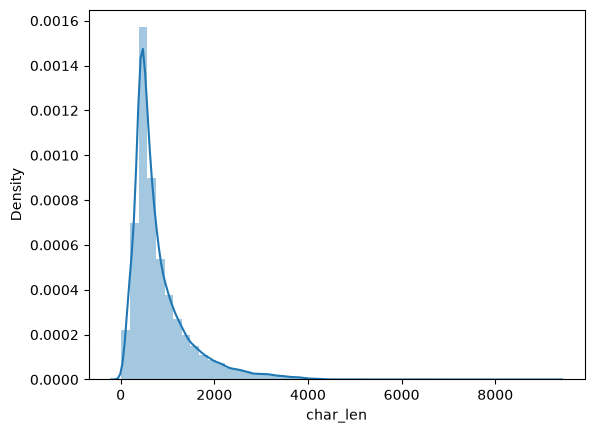

In [28]:
# here we tried plotting  a distribution plot to check wether the feature we are making is helpful or not
import seaborn as sns
sns.distplot(df['char_len'])

<Axes: xlabel='char_len', ylabel='Count'>

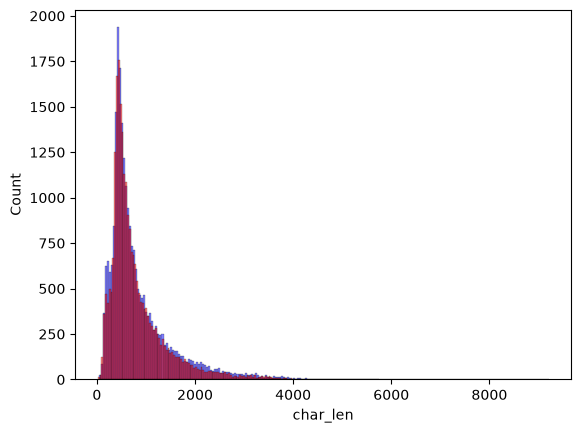

In [29]:
sns.histplot(
    df[df['sentiment'] == 'positive']['char_len'],
    color='blue',
    label='Positive',
    alpha=0.5,
)
sns.histplot(
    df[df['sentiment'] == 'negative']['char_len'],
    color='red',
    label='Negative',
    alpha=0.5,
)


<Axes: xlabel='words_length', ylabel='Count'>

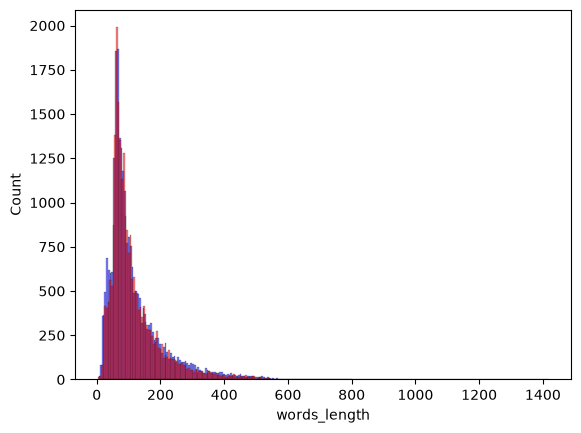

In [30]:
sns.histplot(
    df[df['sentiment'] == 'positive']['words_length'],
    color='blue',
    label='Positive',
    alpha=0.5,
)
sns.histplot(
    df[df['sentiment'] == 'negative']['words_length'],
    color='red',
    label='Negative',
    alpha=0.5,
)


unfortunately the char length and word length both arent giving clear differentiation


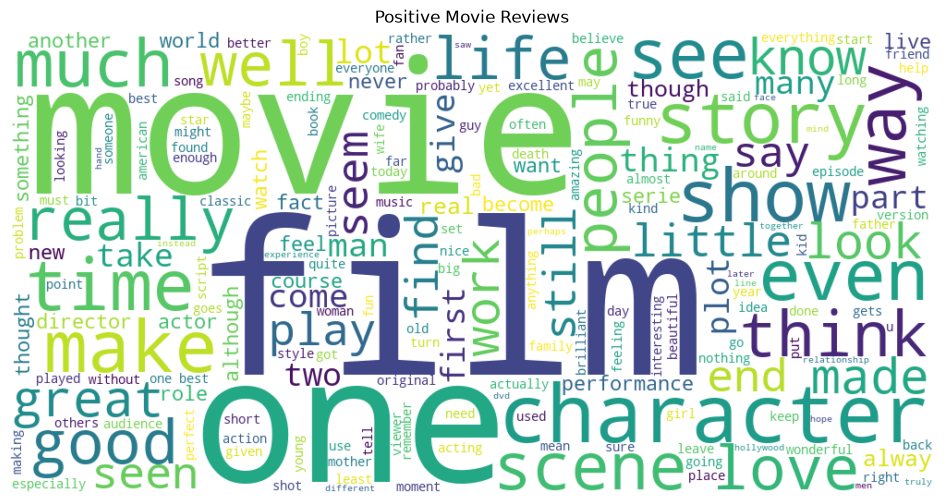

In [31]:
# word cloud 
from wordcloud import WordCloud
import matplotlib.pyplot as plt

positive_text = ' '.join(
    df[df['sentiment'] == 'positive']['tokenized_review']
    .apply(lambda words: ' '.join(words))
)

wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color='white'
).generate(positive_text)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Positive Movie Reviews')
plt.show()

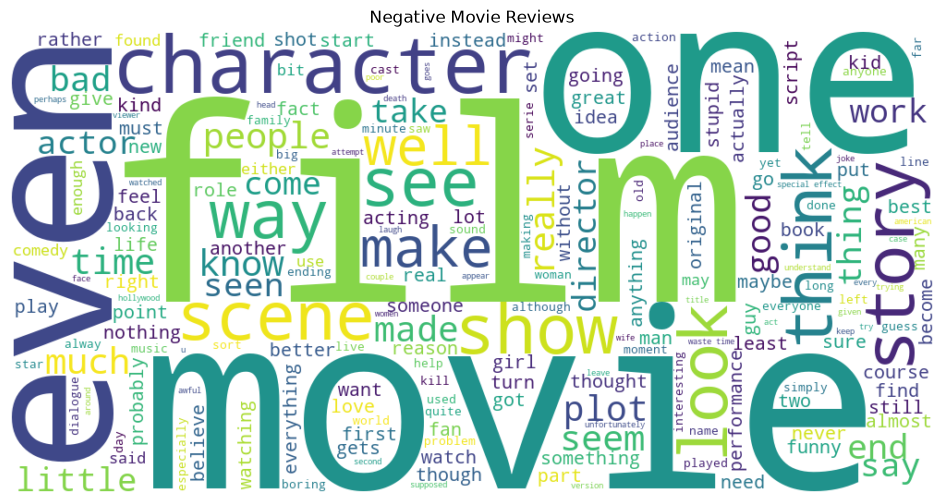

In [32]:
# for negative words
negative_text = ' '.join(
    df[df['sentiment'] == 'negative']['tokenized_review']
    .apply(lambda words: ' '.join(words))
)

wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color='white'
).generate(negative_text)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Negative Movie Reviews')
plt.show()

# Vectorization — Bag of Words
 ## Use CountVectorizer to represent reviews as word-count vectors and encode sentiment labels.

In [35]:
# bag of words

from sklearn.feature_extraction.text import CountVectorizer

cv = CountVectorizer(max_features=5000)

x = cv.fit_transform(df['review'])
y = df['sentiment'].apply(lambda x: 1 if x == 'positive' else 0).values



In [36]:
print("Shape of feature matrix X:", x.shape)
print("Shape of label array y:", y.shape)

Shape of feature matrix X: (50000, 5000)
Shape of label array y: (50000,)


In [39]:
bow_df = pd.DataFrame(
    x[:5].toarray(),
    columns=cv.get_feature_names_out()
)

bow_df.iloc[:, :50]

,10,100,1010,11,110,12,13,13th,14,15,...,20th,210,23,24,25,2nd,30,3000,30s,310
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


# Dimensionality Reduction — PCA
## Reduce a sample of the Bag of Words data to two principal components and visualize it with Seaborn.

In [40]:
from sklearn.decomposition import PCA

# Select a sample of 2000 reviews
np.random.seed(42)

sample_size = min(2000, x.shape[0])
indices = np.random.choice(x.shape[0], sample_size, replace=False)

# Convert the sampled sparse matrix to a dense array
x_sample = x[indices].toarray()
y_sample = y[indices]

# Reduce 5000 features to 2 components
pca = PCA(n_components=2, random_state=42)

x_pca = pca.fit_transform(x_sample)

print("Original shape:", x_sample.shape)
print("Reduced shape:", x_pca.shape)
print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance explained:", pca.explained_variance_ratio_.sum())

Original shape: (2000, 5000)
Reduced shape: (2000, 2)
Explained variance ratio: [0.05567599 0.03946569]
Total variance explained: 0.09514167692386388


In [41]:
pca_df = pd.DataFrame({
    'PC1': x_pca[:, 0],
    'PC2': x_pca[:, 1],
    'Sentiment': np.where(y_sample == 1, 'Positive', 'Negative')
})

pca_df.head()

,PC1,PC2,Sentiment
0,-1.968655,-0.803295,Positive
1,0.029346,-0.051132,Positive
2,-1.120738,-0.222858,Negative
3,-2.843047,-1.167661,Positive
4,1.313297,2.095753,Negative


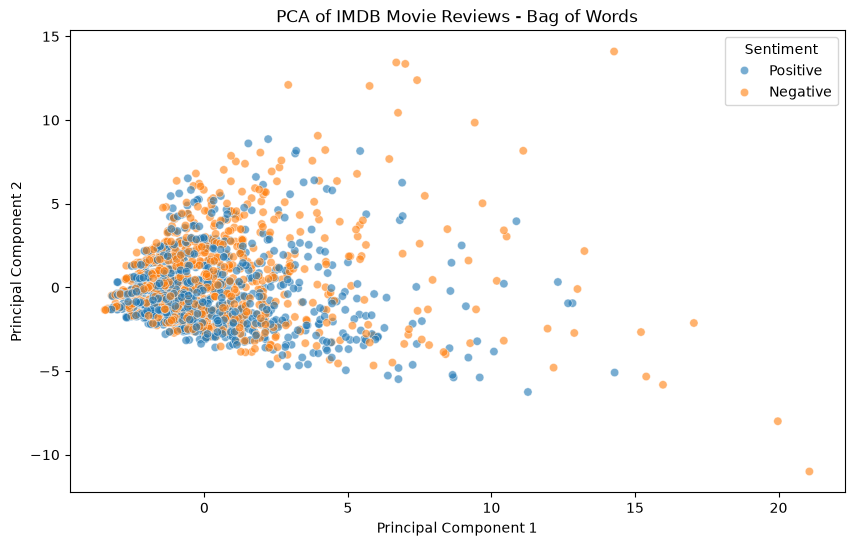

In [42]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    hue='Sentiment',
    alpha=0.6
)

plt.title('PCA of IMDB Movie Reviews - Bag of Words')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Sentiment')
plt.show()
